<a href="https://colab.research.google.com/github/TZBDragon/LinAlg344TZB/blob/main/notebooks/04_which_images.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# What's in the image matters a lot for compressing it

In [2]:
import os
import subprocess
import sys
USER = "tzbdragon"
REPO = "LinAlg344TZB"
if os.path.exists(REPO):
  subprocess.run(['git', '-C', REPO, 'pull'], check=True)
else:
  subprocess.run(
  ['git', 'clone', f'https://github.com/{USER}/{REPO}.git', REPO],
  check=True)
sys.path.insert(0, f'{REPO}/src')
from compress import rank_k_approx, rel_error, predicted_error, compression_ratio, k_for_error
import numpy as np
import matplotlib.pyplot as plt

Generic Imports

In [3]:
N = 256
i, j = np.meshgrid(np.arange(N), np.arange(N), indexing="ij")

def stripes(angle, width=16):
#"""Black and white stripes, tilted by `angle` degrees."""
  t = np.deg2rad(angle)
  return 255.0 * (np.floor((i * np.cos(t) + j * np.sin(t)) / width) % 2)

rng = np.random.default_rng(0)
patterns = {
"stripes, 0 deg": stripes(0),
"stripes, 45 deg": stripes(45),
"checkerboard": 255.0 * ((i // 32 + j // 32) % 2),
"disk": 255.0 * ((i - N/2)**2 + (j - N/2)**2 < (N/3)**2),
"noise": rng.integers(0, 256, size=(N, N)).astype(float),
}


Creates 5 patterns using various methods

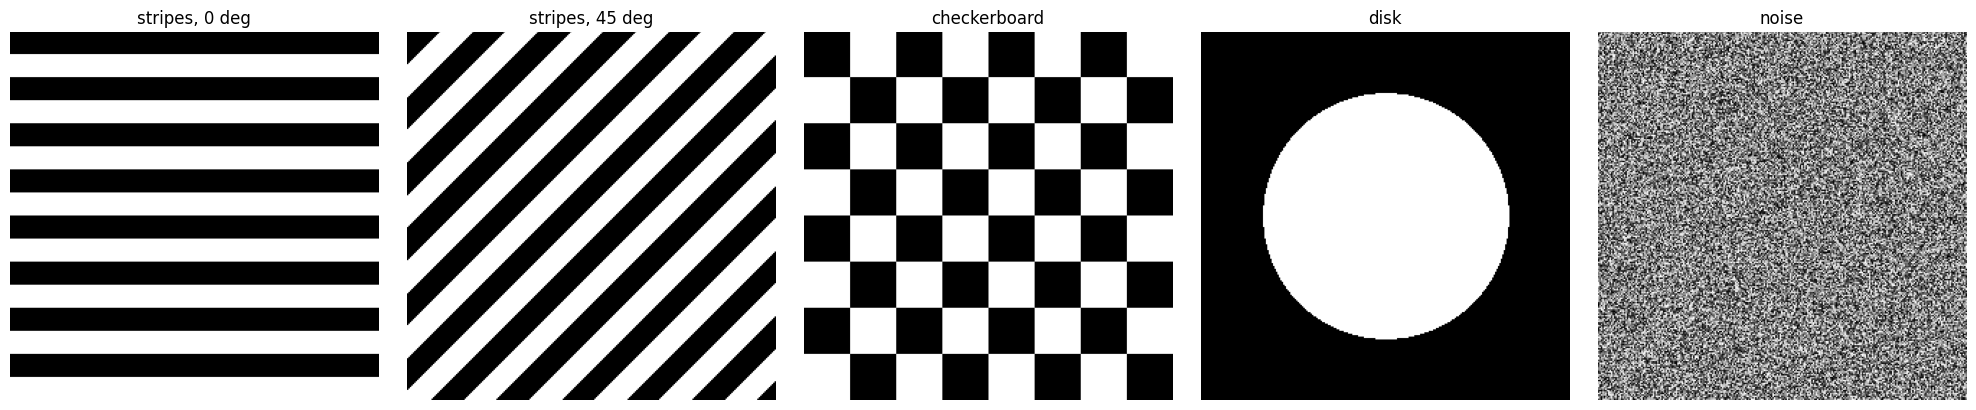

In [4]:
fig, axes = plt.subplots(1, len(patterns), figsize=(20, 4))
for ax, (name, img) in zip(axes, patterns.items()):
    ax.imshow(img, cmap="gray")
    ax.set_title(name)
    ax.axis("off")
plt.tight_layout()
plt.show()

First rank 2, second rank 128, third rank 64, fourth rank 128, fifth almost max rank. Stripes compress best pure noise worst

In [5]:
for name, P in patterns.items():
  s = np.linalg.svd(P, compute_uv=False)
  k5 = k_for_error(s, 0.05)
  print(f"{name:16s} rank = {np.linalg.matrix_rank(P):3d} k for 5% = {k5:3d}"
  f" ratio = {compression_ratio(N, N, k5):6.2f}")

stripes, 0 deg   rank =   1 k for 5% =   1 ratio = 127.75
stripes, 45 deg  rank = 182 k for 5% =  64 ratio =   2.00
checkerboard     rank =   2 k for 5% =   2 ratio =  63.88
disk             rank =  51 k for 5% =  26 ratio =   4.91
noise            rank = 256 k for 5% = 198 ratio =   0.65


compresses the images and displays the compression values

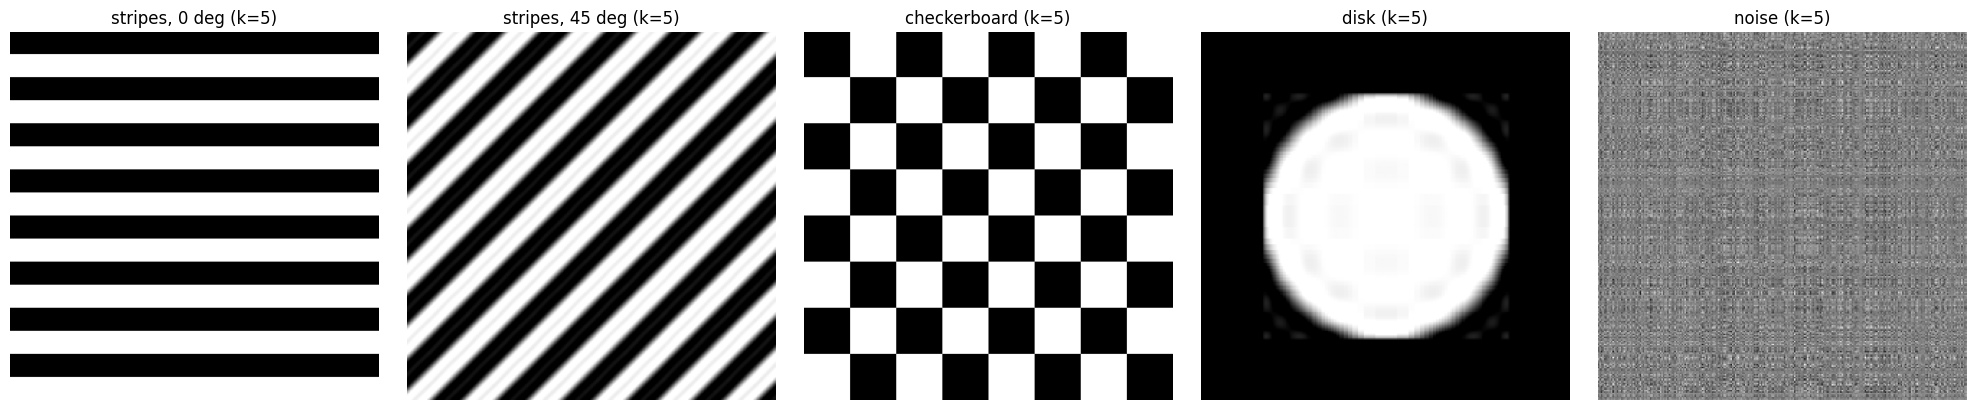

In [6]:
fig, axes = plt.subplots(1, len(patterns), figsize=(20, 4))
for ax, (name, img) in zip(axes, patterns.items()):
    # Approximate with rank k = 5 and clip values to the valid [0, 255] range
    approx_img = np.clip(rank_k_approx(img, 5), 0, 255)
    ax.imshow(approx_img, cmap="gray")
    ax.set_title(f"{name} (k=5)")
    ax.axis("off")
plt.tight_layout()
plt.show()

Show the patterns we made

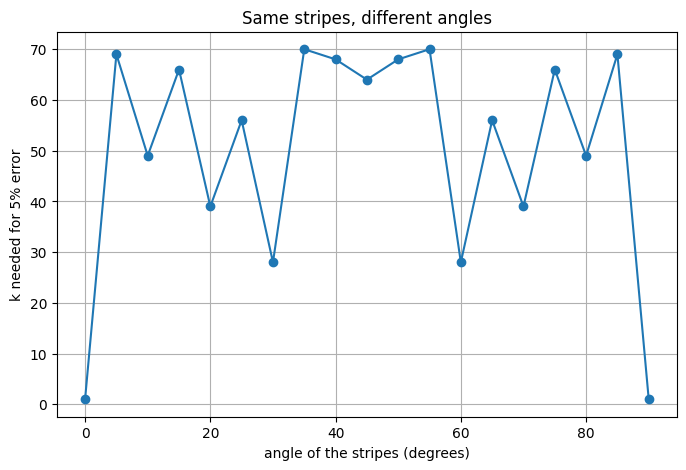

In [7]:
angles = np.arange(0, 91, 5)
ks = [k_for_error(np.linalg.svd(stripes(a), compute_uv=False), 0.05) for a in angles]

plt.figure(figsize=(8, 5))
plt.plot(angles, ks, "o-")
plt.xlabel("angle of the stripes (degrees)")
plt.ylabel("k needed for 5% error")
plt.title("Same stripes, different angles")
plt.grid()
plt.savefig("angles.png", dpi=150)
plt.show()

The plot shows that as the stripes on our demo images rotate they generally become closer to full rank

In [8]:
# Print a region with stripe transitions to analyze the 45 degree stripes
tilted_corner = stripes(45)[10:14, 10:22] / 255.0
print(tilted_corner)

[[0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
 [0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
 [0. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]]


As you move across rows you see that the stripes offset each row uniquely from the next meaning that it is much harder to compress

Gradient will give a k error of less than 32
Checkerboard will be close to full rank k error

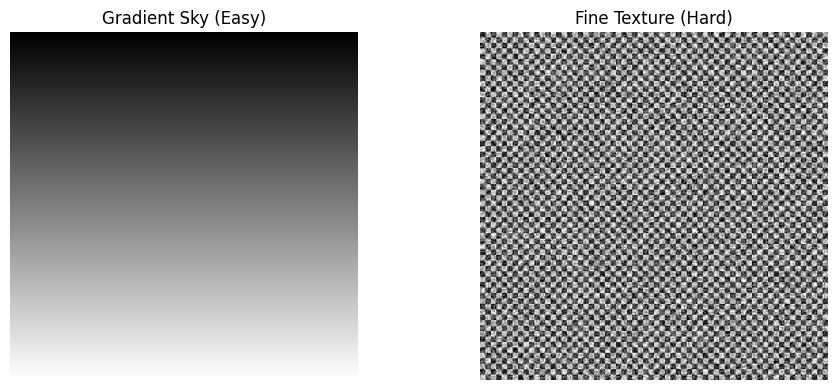

Gradient Sky (Easy)  rank =   1 | k for 5% =   1 | ratio = 127.75
Fine Texture (Hard)  rank = 256 | k for 5% = 164 | ratio =   0.78


In [9]:
# Exercise 2: Design and test two human-meaningful images
# 1. Easy to compress (Smooth gradient/sky): low-rank features
# 2. Hard to compress (High detail checkerboard/complex texture): high-rank features

N = 256
y, x = np.meshgrid(np.arange(N), np.arange(N), indexing="ij")

# Pattern A: Vertical/Horizontal Smooth Gradient (simulating a sky or shadow)
# Highly redundant rows/columns
easy_image = 255.0 * (y / N)

# Pattern B: Fine-grained complex checkerboard texture with overlapping high frequency noise
# Lots of sharp transitions and high-frequency content
hard_image = 127.5 * ((x // 4 + y // 4) % 2) + rng.uniform(0, 127.5, size=(N, N))

custom_patterns = {
    "Gradient Sky (Easy)": easy_image,
    "Fine Texture (Hard)": hard_image
}

# Display the custom designs
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, img) in zip(axes, custom_patterns.items()):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(name)
    ax.axis("off")
plt.tight_layout()
plt.show()

# Evaluate rank and compression qualities
for name, P in custom_patterns.items():
    s = np.linalg.svd(P, compute_uv=False)
    k5 = k_for_error(s, 0.05)
    print(f"{name:20s} rank = {np.linalg.matrix_rank(P):3d} | k for 5% = {k5:3d} | ratio = {compression_ratio(N, N, k5):6.2f}")

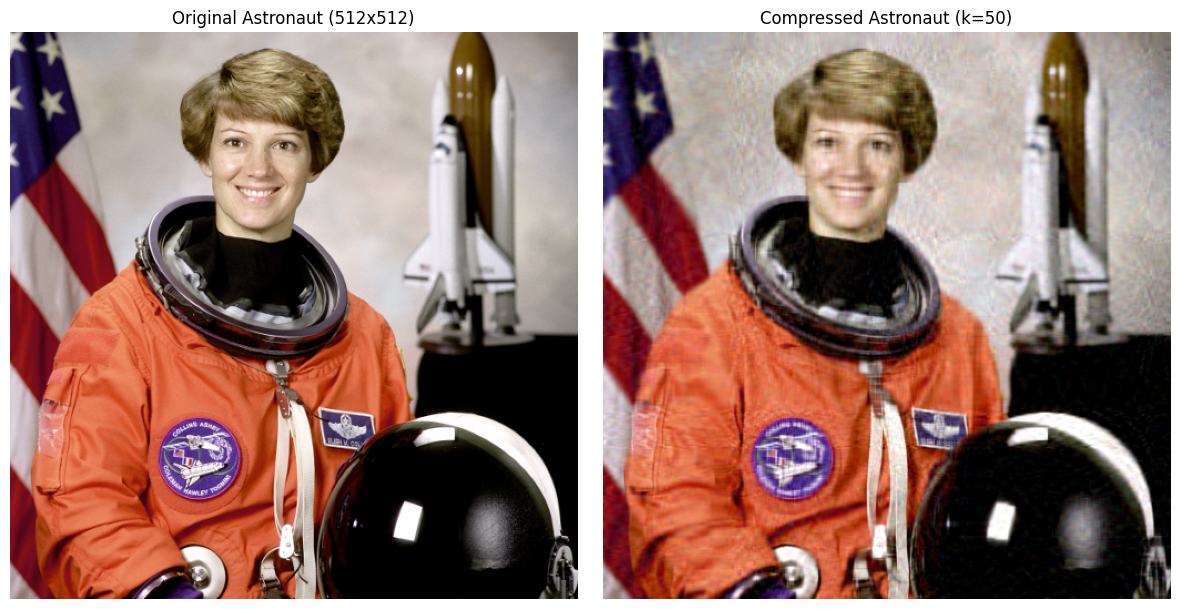

Overall Relative Error: 7.87%
Storage Compression Ratio: 5.12x


In [10]:
# Exercise 3: Compress the 3-channel (color) astronaut image using SVD
from skimage import data

# 1. Load the astronaut image (512x512x3 uint8 array)
astronaut = data.astronaut().astype(float)
height, width, channels = astronaut.shape
k_target = 50

# 2. Compress each color channel separately and recombine
compressed_channels = []
original_norms_sq = 0.0
error_norms_sq = 0.0

for c in range(channels):
    channel_img = astronaut[:, :, c]
    # SVD on this channel
    U, S, Vt = np.linalg.svd(channel_img, full_matrices=False)

    # Reconstruct at rank k = 50
    approx_channel = rank_k_approx(channel_img, k_target)
    compressed_channels.append(approx_channel)

    # Calculate error norms for the overall relative error
    original_norms_sq += np.linalg.norm(channel_img, "fro")**2
    error_norms_sq += np.linalg.norm(channel_img - approx_channel, "fro")**2

# Recombine and clip to valid [0, 255] range for display
compressed_astronaut = np.stack(compressed_channels, axis=2)
compressed_astronaut_clipped = np.clip(compressed_astronaut, 0, 255).astype(np.uint8)

# 3. Compute relative error across all channels
overall_rel_error = np.sqrt(error_norms_sq) / np.sqrt(original_norms_sq)

# 4. Compute storage compression ratio for 3 channels
# Original storage = 3 * H * W
# Compressed storage = 3 * (k * (H + W + 1))
ratio = (height * width * channels) / (channels * k_target * (height + width + 1))

# 5. Display the results
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(astronaut.astype(np.uint8))
axes[0].set_title("Original Astronaut (512x512)")
axes[0].axis("off")

axes[1].imshow(compressed_astronaut_clipped)
axes[1].set_title(f"Compressed Astronaut (k={k_target})")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print(f"Overall Relative Error: {overall_rel_error * 100:.2f}%")
print(f"Storage Compression Ratio: {ratio:.2f}x")

Letters tend to be treated as background noise, so unless they are optimized for they can easily be destroyed

What we found: 4